# Implementation and Time Analysis of Factorial (Iterative vs Recursive)

This notebook implements the factorial of a number `n` (`n!`) using two approaches:

1. **Iterative Method** — using a loop
2. **Recursive Method** — using a function that calls itself

For each method you will find:
- Python implementation
- User input (enter your own value of `n`)
- Runtime measurement (using `time` module)
- Time Complexity
- Space Complexity

At the end, both methods are compared for correctness and runtime across increasing values of `n`.


In [1]:
# Common imports used throughout the notebook
import time
import sys
import matplotlib.pyplot as plt

def get_user_number(demo_value=None):
    """Takes a single non-negative integer n to compute n! for.

    - Interactive use: call get_user_number() with NO arguments. It will
      prompt you with input() to type your own value, e.g. 10
    - This notebook (pre-run with saved outputs): each demo cell below calls
      get_user_number(\"10\") with a fixed value instead, purely so the
      notebook can be executed top-to-bottom non-interactively and still show
      real output. Remove the argument any time you want to type your own
      number instead.
    """
    raw = demo_value if demo_value is not None else input("Enter a non-negative integer n to compute n!: ")
    try:
        n = int(raw)
        if n < 0:
            print("Factorial is not defined for negative numbers. Using n = 0 instead.")
            n = 0
    except ValueError:
        print("Invalid input detected, defaulting n to 5.")
        n = 5
    return n


## 1. Iterative Method

Uses a simple `for` loop to multiply the numbers from `1` to `n` together.
`0!` is defined as `1` (the empty product).


In [2]:
def factorial_iterative(n):
    result = 1
    for i in range(2, n + 1):
        result *= i
    return result


In [3]:
# --- Iterative Factorial: User Input + Runtime ---
# Replace the argument below with nothing, i.e. get_user_number(), to type your own value.
n = get_user_number("10")
print(f"n = {n}")

start = time.time()
result = factorial_iterative(n)
end = time.time()

print(f"{n}! (iterative) = {result}")
print(f"Runtime           : {(end - start) * 1000:.6f} ms")


n = 10
10! (iterative) = 3628800
Runtime           : 0.035763 ms


**Time Complexity:** `O(n)` — the loop runs `n - 1` times regardless of input value (no best/worst case variation for a fixed `n`).

**Space Complexity:** `O(1)` auxiliary space — only a single `result` variable is used (ignoring the space needed to store the potentially very large result integer itself, which grows with `n`).


## 2. Recursive Method

Defines factorial in terms of itself: `n! = n * (n-1)!`, with the base case `0! = 1! = 1`.
Each call waits on the result of the next, building up a call stack `n` levels deep.


In [4]:
def factorial_recursive(n):
    if n <= 1:
        return 1
    return n * factorial_recursive(n - 1)


In [5]:
# --- Recursive Factorial: User Input + Runtime ---
# Replace the argument below with nothing, i.e. get_user_number(), to type your own value.
n = get_user_number("10")
print(f"n = {n}")

# Python's default recursion limit is ~1000; raise it a bit so larger demo
# values (used later in the comparison section) don't hit RecursionError.
sys.setrecursionlimit(10000)

start = time.time()
result = factorial_recursive(n)
end = time.time()

print(f"{n}! (recursive) = {result}")
print(f"Runtime            : {(end - start) * 1000:.6f} ms")


n = 10
10! (recursive) = 3628800
Runtime            : 0.031233 ms


**Time Complexity:** `O(n)` — exactly `n` recursive calls are made.

**Space Complexity:** `O(n)` — each call adds a new frame to the call stack, and all `n` frames exist simultaneously at the deepest point of recursion, unlike the iterative version's constant space.

**Caveat:** Python has a default recursion depth limit (commonly 1000). For very large `n`, the recursive version will raise a `RecursionError` unless `sys.setrecursionlimit()` is increased, and even then, deep recursion consumes real stack memory and is slower per-call than a loop.


## 3. Verifying Correctness

Quick sanity check that both methods agree for a range of values.


In [6]:
for test_n in [0, 1, 5, 10, 20]:
    it = factorial_iterative(test_n)
    rec = factorial_recursive(test_n)
    status = "OK" if it == rec else "MISMATCH"
    print(f"n={test_n:<3} iterative={it:<25} recursive={rec:<25} [{status}]")


n=0   iterative=1                         recursive=1                         [OK]
n=1   iterative=1                         recursive=1                         [OK]
n=5   iterative=120                       recursive=120                       [OK]
n=10  iterative=3628800                   recursive=3628800                   [OK]
n=20  iterative=2432902008176640000       recursive=2432902008176640000       [OK]


## 4. Runtime Comparison: Iterative vs Recursive

The cell below computes `n!` using both methods for increasing values of `n`
and times each, then plots the results. Recursive calls carry extra overhead
(function call setup, stack frame management) compared to a plain loop, so we
expect the recursive version to be measurably slower even though both are
`O(n)` in time.


In [7]:
# --- Compare Iterative vs Recursive across increasing n ---
n_values = [100, 500, 1000, 2000, 3000]
iter_times = []
rec_times = []

sys.setrecursionlimit(10000)

for n in n_values:
    start = time.time()
    factorial_iterative(n)
    iter_times.append((time.time() - start) * 1000)

    start = time.time()
    factorial_recursive(n)
    rec_times.append((time.time() - start) * 1000)

print(f"{'n':<8}{'Iterative (ms)':<18}{'Recursive (ms)':<18}")
for n, it, rc in zip(n_values, iter_times, rec_times):
    print(f"{n:<8}{it:<18.4f}{rc:<18.4f}")


n       Iterative (ms)    Recursive (ms)    
100     0.0072            0.0098            
500     0.0963            0.3448            
1000    0.1826            0.5734            
2000    0.6425            1.4331            
3000    1.4608            3.4125            


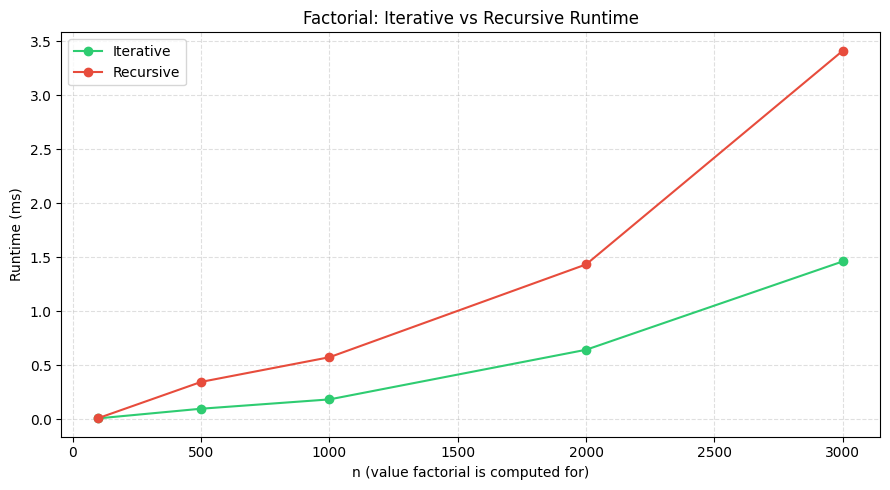

In [8]:
# --- Line chart of runtimes ---
plt.figure(figsize=(9, 5))
plt.plot(n_values, iter_times, marker='o', label='Iterative', color='#2ecc71')
plt.plot(n_values, rec_times, marker='o', label='Recursive', color='#e74c3c')
plt.xlabel("n (value factorial is computed for)")
plt.ylabel("Runtime (ms)")
plt.title("Factorial: Iterative vs Recursive Runtime")
plt.legend()
plt.grid(True, ls="--", alpha=0.4)
plt.tight_layout()
plt.show()


## Summary Table

| Method     | Time Complexity | Space Complexity | Risk of Stack Overflow | Relative Speed  |
|------------|------------------|-------------------|--------------------------|-------------------|
| Iterative  | O(n)             | O(1)              | No                       | Faster            |
| Recursive  | O(n)             | O(n)              | Yes (for large n)        | Slower (call overhead) |

**Notes:**
- Both methods do the same amount of "work" (`n` multiplications) — the difference is entirely in overhead and memory usage.
- The iterative method is generally preferred in production code for factorial specifically, since it avoids both the stack-depth limit and function-call overhead.
- The recursive method is a classic teaching example for understanding recursion, base cases, and the call stack, and generalizes better to problems that don't have an obvious iterative structure (e.g., tree traversal).
- For very large `n`, both `n!` itself and the time to compute it grow quickly — Python integers grow arbitrarily large automatically, but the multiplication cost per step also increases with the size of the running product (this notebook's O(n) analysis assumes fixed-size word multiplication; in practice, big-integer multiplication makes the true cost somewhat higher for very large n).
